#Classification & Model Evaluation Deep Dive
Dataset: “Customer Churn”

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report
)

import matplotlib.pyplot as plt

In [2]:
df = pd.DataFrame({
    "monthly_spend":      [25, 35, 40, 45, 55, 60, 65, 70, 80, 85, 90, 95, 100, 110, 120, 130, 45, 50, 75, 105],
    "tenure_months":      [1,  2,  3,  4,  6,  8,  10, 12, 14, 16, 18, 20,  22,  24,  30,  36,  5,  7,  13,  26],
    "contract_type":      ["month-to-month","month-to-month","month-to-month","month-to-month",
                           "1-year","1-year","1-year","1-year",
                           "2-year","2-year","2-year","2-year",
                           "2-year","2-year","2-year","2-year",
                           "month-to-month","1-year","month-to-month","1-year"],
    "support_tickets":    [3,  2,  4,  3,  1,  2,  2,  1,  0,  1,  0,  1,  0,  0,  1,  0,  3,  2,  2,  1],
    "late_payments":      [2,  1,  2,  1,  0,  1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  2,  0],

    "churn_score":        [92, 85, 88, 80, 30, 45, 40, 35, 10, 20, 15, 25,  5,  8, 12,  7, 78, 55, 70, 50],

    # Target
    "churn":              [1,  1,  1,  1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  0,  1,  0]
})

df.head()

,monthly_spend,tenure_months,contract_type,support_tickets,late_payments,churn_score,churn
0,25,1,month-to-month,3,2,92,1
1,35,2,month-to-month,2,1,85,1
2,40,3,month-to-month,4,2,88,1
3,45,4,month-to-month,3,1,80,1
4,55,6,1-year,1,0,30,0


churn = 1 means customer left

churn is imbalanced (more zeros than ones)


# Task A — Problem Framing (Write Answers)

Answer in markdown:

* Is this classification or regression? Why?

* What is the target variable?

* Which column is leakage and why?

- it's classification, since the targets we will be predicting are two classes (churns being 0 and 1)
- 'churn' column is the target variable
- 'churn score' will probably causse data leakage, because churn is dependant on the score (being > 50 = 1)

In [3]:
df[df['churn_score'] >= 50].head()

,monthly_spend,tenure_months,contract_type,support_tickets,late_payments,churn_score,churn
0,25,1,month-to-month,3,2,92,1
1,35,2,month-to-month,2,1,85,1
2,40,3,month-to-month,4,2,88,1
3,45,4,month-to-month,3,1,80,1
16,45,5,month-to-month,3,1,78,1


In [4]:
df[df['churn_score'] <= 50].head()

,monthly_spend,tenure_months,contract_type,support_tickets,late_payments,churn_score,churn
4,55,6,1-year,1,0,30,0
5,60,8,1-year,2,1,45,0
6,65,10,1-year,2,0,40,0
7,70,12,1-year,1,0,35,0
8,80,14,2-year,0,0,10,0


#Task B — Prepare Features (Drop Leakage + Encode)
##Requirements:

* Drop `churn_score`

* One-hot encode `contract_type`

In [5]:
X = df.drop(columns=["churn_score", "churn"])
y=df["churn"]
X=pd.get_dummies(X, columns=["contract_type"], drop_first=True)
X.head()

,monthly_spend,tenure_months,support_tickets,late_payments,contract_type_2-year,contract_type_month-to-month
0,25,1,3,2,False,True
1,35,2,2,1,False,True
2,40,3,4,2,False,True
3,45,4,3,1,False,True
4,55,6,1,0,False,False


#Task C — Train Logistic Regression + Metrics

In [6]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)
log_model=LogisticRegression(max_iter=1000)
log_model.fit(X_train,y_train)
y_pred=log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:, 1]
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification report:\n", classification_report(y_test, y_pred, zero_division=0))

Confusion matrix:
 [[3 1]
 [0 2]]

Accuracy: 0.8333333333333334
Precision: 0.6666666666666666
Recall: 1.0
F1: 0.8

Classification report:
               precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.67      1.00      0.80         2

    accuracy                           0.83         6
   macro avg       0.83      0.88      0.83         6
weighted avg       0.89      0.83      0.84         6



#Task D — Decision Tree + Metrics

In [7]:
deci=DecisionTreeClassifier(max_depth=3, random_state=42)
deci.fit(X_train,y_train)
y_pred=deci.predict(X_test)
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification report:\n", classification_report(y_test, y_pred, zero_division=0))

Confusion matrix:
 [[2 2]
 [0 2]]

Accuracy: 0.6666666666666666
Precision: 0.5
Recall: 1.0
F1: 0.6666666666666666

Classification report:
               precision    recall  f1-score   support

           0       1.00      0.50      0.67         4
           1       0.50      1.00      0.67         2

    accuracy                           0.67         6
   macro avg       0.75      0.75      0.67         6
weighted avg       0.83      0.67      0.67         6



#Task E — ROC-AUC (For Logistic Regression)

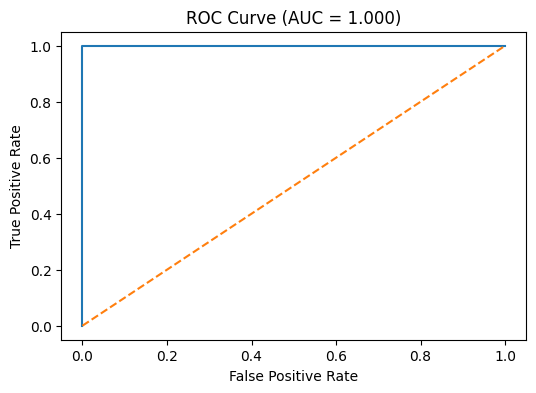

In [8]:
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1], linestyle="--")
plt.title(f"ROC Curve (AUC = {auc:.3f})")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

#Task F — Threshold Tuning

Try thresholds:

* 0.5
* 0.3

-> Compare confusion matrix and recall.

In [10]:
def eval_threshold(th):
    pred_th = (y_prob >= th).astype(int)
    return {
        "threshold": th,
        "cm": confusion_matrix(y_test, pred_th),
        "precision": precision_score(y_test, pred_th, zero_division=0),
        "recall": recall_score(y_test, pred_th, zero_division=0),
        "f1": f1_score(y_test, pred_th, zero_division=0)
    }
res_05 = eval_threshold(0.5)
res_03 = eval_threshold(0.3)

res_05, res_03

({'threshold': 0.5,
  'cm': array([[3, 1],
         [0, 2]]),
  'precision': 0.6666666666666666,
  'recall': 1.0,
  'f1': 0.8},
 {'threshold': 0.3,
  'cm': array([[2, 2],
         [0, 2]]),
  'precision': 0.5,
  'recall': 1.0,
  'f1': 0.6666666666666666})

In [ ]:
# lowering the threshold from 0.5 to 0.3 increased false positives from 1 to 2,
# while recall stayed at 100%. Precision decreased from 67% to 50%,
# meaning the lower threshold did not improve the model's performance in this case

# Reflection (8–10 lines)

* Write a short paragraph explaining:
* Why accuracy alone can be misleading here
* Which model you would choose and why
* When you prefer recall vs precision
* What happened when you changed threshold

In [ ]:
# accuracy can be misleading with imbalanced data
# a model may favor the majority class
# I would choose Logistic Regression over Decision Tree, since it achieved higher accuracy (83% vs. 67%).
# both models achieved 100% recall.
# recall matters when missing churners is costly, while precision matters when false alarms are costly.
# lowering the threshold increased false positives
# recall stayed the same, but precision decreased
# more test data is needed for reliable conclusions